# RoadSafe Chicago | Partie 07 : Tests statistiques

**Projet** : étude de l'accidentologie routière à Chicago (Open Data, API Socrata)
**Données** : 112 056 accidents enregistrés en 2024 (`data/processed/crashes_2024.parquet`)
**Problématique** : *Comment évoluent la fréquence et la gravité des accidents routiers à Chicago, et quels facteurs sont associés à leur gravité ?*

---

### Objectif

Les parties 05 et 06 ont mis en évidence des écarts de gravité. Cette partie vérifie s'ils sont **statistiquement établis**, et surtout **quelle est leur ampleur** : on passe de « ce graphique semble montrer » à « les données permettent d'étayer cette conclusion ».

### Hypothèses testées

| Hypothèse | Question | Méthode |
|---|---|---|
| **H1** | La proportion d'accidents graves varie-t-elle selon la luminosité ? | Test du Chi², V de Cramér, ratios de risque avec IC à 95 % |
| **H2** | Les accidents se répartissent-ils uniformément sur l'année ? | Test d'adéquation du Chi², à durée de mois égale |
| **H3** | L'association entre luminosité et gravité persiste-t-elle après ajustement sur les autres facteurs ? | Régression logistique explicative, odds ratios avec IC à 95 % |

### Protocole appliqué à chaque test

1. Formuler **H0** et **H1** avant de consulter le résultat.
2. Définir la population, l'unité d'analyse et les groupes comparés.
3. Vérifier les **conditions d'application** du test.
4. Rapporter la **taille d'effet** et son **intervalle de confiance**, pas seulement la p-value.
5. Interpréter l'intérêt métier, les biais possibles et les limites.

### Précautions de lecture

- Avec plus de 100 000 accidents, **presque tout écart devient statistiquement significatif**. La p-value indique qu'un effet existe, la **taille d'effet** indique s'il compte.
- Une association statistique **ne démontre pas une causalité**. Les données décrivent des accidents enregistrés, sans information sur l'exposition au trafic.
- La version complète de H2 (évolution entre années) nécessite l'extension à 2018-2025. Elle est ici testée sur la répartition mensuelle de 2024.


## Librairies 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy import stats
import statsmodels.formula.api as smf

sns.set_theme(style="whitegrid")
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
df = pd.read_parquet("../data/processed/crashes_2024.parquet")
df.head()


,crash_record_id,crash_date,posted_speed_limit,traffic_control_device,device_condition,weather_condition,lighting_condition,first_crash_type,trafficway_type,alignment,...,delay_valid,injury_info_available,is_injury,is_fatal,is_severe,is_weekend,time_slot,season,is_dark,speed_class
0,5082d6e9f9c5c96660e7ec7fd416549e50d3130af3fc5c...,2024-06-27 13:45:00,10,NO CONTROLS,NO CONTROLS,CLEAR,DAYLIGHT,PARKED MOTOR VEHICLE,PARKING LOT,STRAIGHT AND LEVEL,...,True,True,False,False,False,False,Journée (10-15h),Été,False,≤20
1,fd34aa4f12f00106b32134531fc6e805590dbe89fef502...,2024-06-22 18:07:00,30,NO CONTROLS,NO CONTROLS,CLEAR,DAYLIGHT,PARKED MOTOR VEHICLE,NOT DIVIDED,STRAIGHT AND LEVEL,...,True,True,False,False,False,True,Soir (16-19h),Été,False,25-30
2,f0a652bf48a8c08c8a26cc981e39ed757cd41f8a771761...,2024-06-23 08:41:00,10,NO CONTROLS,NO CONTROLS,CLEAR,DAYLIGHT,REAR TO REAR,PARKING LOT,STRAIGHT AND LEVEL,...,True,True,False,False,False,True,Matin (6-9h),Été,False,≤20
3,973cda531480f4006c44691e5cc8931b9fd9d719a21264...,2024-06-19 07:35:00,30,NO CONTROLS,NO CONTROLS,CLEAR,DAYLIGHT,TURNING,T-INTERSECTION,STRAIGHT AND LEVEL,...,True,True,False,False,False,False,Matin (6-9h),Été,False,25-30
4,e66fd58b2afc22ec6aa176f149d17467d49f7ae1c83910...,2024-07-07 20:47:00,30,NO CONTROLS,NO CONTROLS,CLEAR,"DARKNESS, LIGHTED ROAD",PARKED MOTOR VEHICLE,OTHER,STRAIGHT AND LEVEL,...,True,True,True,False,False,True,Nuit (20-23h),Été,True,25-30


In [3]:
# Map des conditions d'éclairage en français pour les graphiques

lum_map = {"DAYLIGHT": "Jour", "DARKNESS, LIGHTED ROAD": "Nuit éclairée",
           "DARKNESS": "Nuit non éclairée", "DUSK": "Aube / crépuscule", "DAWN": "Aube / crépuscule"}
df["lum_groupe"] = df["lighting_condition"].astype(str).map(lum_map)


In [4]:

# Sauvegarde des figures
def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


In [5]:
# Definition de la fonction pour calculer le V de Cramer

def cramers_v(table):
    """Taille d'effet du Chi² : 0 = aucune association, 1 = association parfaite."""
    chi2 = stats.chi2_contingency(table)[0]
    n = table.to_numpy().sum()
    return np.sqrt(chi2 / (n * (min(table.shape) - 1)))

## H1 : La gravité varie-t-elle selon la luminosité ?

**H0** : la proportion d'accidents graves est la même quelle que soit la luminosité. **H1** : elle diffère selon la luminosité.

In [6]:
# Test du Chi² pour l'association entre la gravité des accidents et la luminosité


d = df.dropna(subset=["lum_groupe", "is_severe"])
table = pd.crosstab(d["lum_groupe"], d["is_severe"])
chi2, p, ddl, attendus = stats.chi2_contingency(table)

print("Table de contingence :\n", table, "\n")
print(f"Condition : effectif attendu minimum = {attendus.min():.0f} (doit être ≥ 5)")
print(f"Chi² = {chi2:.1f} | ddl = {ddl} | p-value = {p:.2e}")
print(f"V de Cramér = {cramers_v(table):.3f}")

Table de contingence :
 is_severe          False  True 
lum_groupe                     
Aube / crépuscule   4774     86
Jour               69976    952
Nuit non éclairée   4901     93
Nuit éclairée      23372    580 

Condition : effectif attendu minimum = 79 (doit être ≥ 5)
Chi² = 132.2 | ddl = 3 | p-value = 1.82e-28
V de Cramér = 0.036


**Analyse.** Les conditions du test sont réunies (effectif attendu minimum de 79, bien au dessus de 5). La p-value est extrêmement faible, mais avec plus de 100 000 observations, un écart même minime devient significatif : c'est le V de Cramér (0,036, effet faible) qui renseigne sur l'ampleur de l'association.

In [7]:
# Calcul du ratio de risque (RR) et de son intervalle de confiance à 95% pour chaque groupe par rapport au groupe de référence "Jour"

def ratio_risque(groupe, reference="Jour", alpha=0.05):
    exp = d[d["lum_groupe"] == groupe]["is_severe"]
    ref = d[d["lum_groupe"] == reference]["is_severe"]
    a, n1, c, n0 = exp.sum(), len(exp), ref.sum(), len(ref)
    rr = (a / n1) / (c / n0)
    se = np.sqrt(1/a - 1/n1 + 1/c - 1/n0)  # erreur standard du log(RR)
    z = stats.norm.ppf(1 - alpha / 2)
    return {"groupe": groupe, "taux_%": a / n1 * 100, "n": n1, "ratio_vs_jour": rr,
            "ic_bas": np.exp(np.log(rr) - z * se), "ic_haut": np.exp(np.log(rr) + z * se)}

groupes = ["Nuit éclairée", "Nuit non éclairée", "Aube / crépuscule"]
# Correction de Bonferroni : 3 comparaisons → seuil de 0,05 / 3 par comparaison
rr_table = pd.DataFrame([ratio_risque(g, alpha=0.05 / len(groupes)) for g in groupes]).round(3)
rr_table

,groupe,taux_%,n,ratio_vs_jour,ic_bas,ic_haut
0,Nuit éclairée,2.422,23952,1.804,1.592,2.044
1,Nuit non éclairée,1.862,4994,1.387,1.072,1.795
2,Aube / crépuscule,1.770,4860,1.318,1.009,1.722


**Analyse.** Les ratios de risque donnent une lecture concrète : par rapport au jour, la gravité est multipliée par 1,8 la nuit sur voie éclairée, et par environ 1,3 à 1,4 dans les autres conditions de faible luminosité. Les intervalles sont calculés au seuil corrigé de Bonferroni (0,05 / 3) ; aucun ne contient 1.

## H2 : Les accidents se répartissent-ils uniformément sur l'année ?

**H0** : à durée égale, chaque mois reçoit la même part d'accidents. **H1** : la répartition n'est pas uniforme.

In [8]:
# Test du Chi² pour la répartition des accidents par mois

observes = df["crash_month"].value_counts().sort_index()
jours = pd.Series(pd.date_range("2024-01-01", "2024-12-31").month).value_counts().sort_index()
attendus = jours / jours.sum() * observes.sum()  # proportionnel au nombre de jours du mois

chi2, p = stats.chisquare(observes, f_exp=attendus)
n = observes.sum()
w = np.sqrt(chi2 / n)  # taille d'effet de Cohen pour un test d'adéquation

print(f"Chi² = {chi2:.1f} | ddl = {len(observes) - 1} | p-value = {p:.2e}")
print(f"w de Cohen = {w:.3f}")

ecarts = ((observes - attendus) / attendus * 100).round(1)
ecarts.index = ["Jan", "Fév", "Mar", "Avr", "Mai", "Juin", "Juil", "Août", "Sep", "Oct", "Nov", "Déc"]
print("\nÉcart à l'attendu (%) :\n", ecarts)

Chi² = 734.9 | ddl = 11 | p-value = 1.74e-150
w de Cohen = 0.081

Écart à l'attendu (%) :
 Jan    -13.2
Fév    -12.1
Mar     -5.9
Avr      0.8
Mai     13.2
Juin    10.4
Juil     1.2
Août     4.6
Sep      6.9
Oct      4.2
Nov     -2.7
Déc     -7.4
Name: count, dtype: Float64


**Analyse.** La répartition uniforme est nettement rejetée. Les écarts dessinent une saisonnalité claire : déficit de janvier à mars et en décembre, excédent de mai à octobre avec un pic en mai (+13,2 %). C'est ce que montrait déjà la partie 04, désormais confirmé statistiquement.

## H3 : L'association entre luminosité et gravité persiste-t-elle après ajustement ?

Régression logistique avec la gravité (`is_severe`) comme variable expliquée, et comme variables explicatives la luminosité, la vitesse affichée, le type de collision, la météo et le week-end.

In [9]:
# Regression logistique pour prédire la gravité des accidents en fonction de la vitesse, de la météo et du jour de la semaine


m = df[df["speed_valid"] & df["lum_groupe"].isin(["Jour", "Nuit éclairée", "Nuit non éclairée"])].copy()
m = m.dropna(subset=["is_severe"])

# Regroupement des modalités rares pour des estimations stables
top_collisions = m["first_crash_type"].value_counts().drop("UNKNOWN", errors="ignore").head(7).index
m["collision"] = np.where(m["first_crash_type"].isin(top_collisions), m["first_crash_type"].astype(str), "AUTRE")
m["meteo"] = np.where(m["weather_condition"].isin(["CLEAR", "RAIN", "SNOW"]), m["weather_condition"].astype(str), "AUTRE")

m["grave"] = m["is_severe"].astype(int)
m["vitesse"] = m["speed_class"].astype(str)
m["weekend"] = m["is_weekend"].astype(int)

print("Observations :", len(m), "| accidents graves :", m["grave"].sum())

Observations : 99646 | accidents graves : 1623


In [10]:
# Ajustement du modèle logistique avec la formule spécifiée

formule = ("grave ~ C(lum_groupe, Treatment('Jour'))"
           " + C(vitesse, Treatment('25-30'))"
           " + C(collision)"
           " + C(meteo, Treatment('CLEAR'))"
           " + weekend")

modele = smf.logit(formule, data=m).fit(disp=False)

# Odds ratios et IC à 95 %
odds = pd.DataFrame({
    "odds_ratio": np.exp(modele.params),
    "ic_bas": np.exp(modele.conf_int()[0]),
    "ic_haut": np.exp(modele.conf_int()[1]),
    "p_value": modele.pvalues,
}).drop("Intercept").round(3)

# Libellés lisibles
odds.index = (odds.index.str.replace(r"C\((\w+).*?\)\[T\.", r"\1 : ", regex=True).str.replace("]", ""))
print(f"Pseudo R² (McFadden) = {modele.prsquared:.3f}")
odds.sort_values("odds_ratio", ascending=False)

Pseudo R² (McFadden) = 0.135


,odds_ratio,ic_bas,ic_haut,p_value
collision : PEDESTRIAN,7.995,6.793,9.410,0.000
vitesse : 45+,1.890,1.204,2.967,0.006
vitesse : 35-40,1.652,1.407,1.939,0.000
lum_groupe : Nuit éclairée,1.614,1.446,1.803,0.000
collision : AUTRE,1.611,1.357,1.913,0.000
weekend,1.415,1.272,1.574,0.000
collision : FIXED OBJECT,1.300,1.048,1.614,0.017
lum_groupe : Nuit non éclairée,1.288,1.030,1.610,0.027
meteo : RAIN,0.896,0.756,1.062,0.206
meteo : SNOW,0.686,0.463,1.016,0.060


**Analyse.** Toutes choses égales par ailleurs, la collision avec un piéton multiplie la cote de gravité par 8, et la nuit sur voie éclairée par 1,6. La référence du type de collision est ANGLE (collision à angle droit), première modalité par ordre alphabétique. Le pseudo R² de 0,135 est modeste mais attendu : les facteurs individuels (vitesse réelle, alcool, ceinture) ne sont pas dans les données.

In [11]:
# Synthèse des tests    
modele = smf.logit(formule, data=m).fit()
print(modele.summary())

Optimization terminated successfully.
         Current function value: 0.072014
         Iterations 9


                           Logit Regression Results                           
Dep. Variable:                  grave   No. Observations:                99646
Model:                          Logit   Df Residuals:                    99629
Method:                           MLE   Df Model:                           16
Date:                Tue, 27 Oct 2026   Pseudo R-squ.:                  0.1346
Time:                        07:30:31   Log-Likelihood:                -7175.9
converged:                       True   LL-Null:                       -8292.2
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                                            coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------------------------
Intercept                                                -3.9788      0.070    -56.999      0.000      -4.116      -3.842
C(

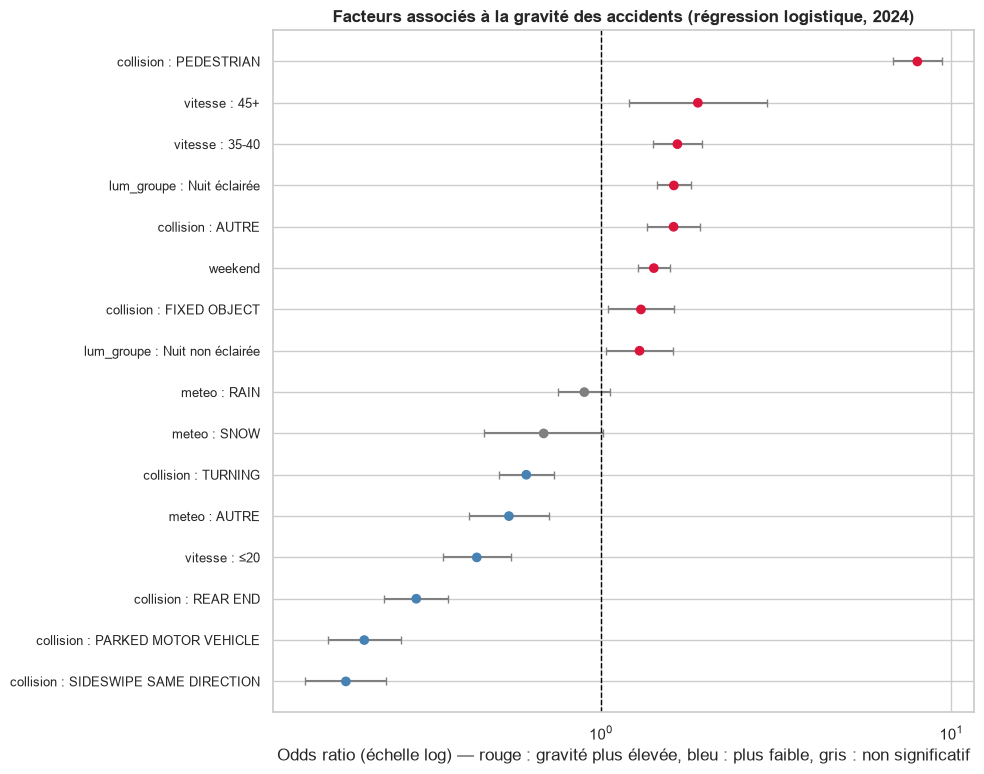

In [12]:

# VIsualisation des odds ratios avec leurs intervalles de confiance à 95 %
o = odds.sort_values("odds_ratio")
couleurs = ["crimson" if lo > 1 else "steelblue" if hi < 1 else "gray"
            for lo, hi in zip(o["ic_bas"], o["ic_haut"])]

fig, ax = plt.subplots(figsize=(10, 0.4 * len(o) + 1.5))
ax.errorbar(o["odds_ratio"], range(len(o)),
            xerr=[o["odds_ratio"] - o["ic_bas"], o["ic_haut"] - o["odds_ratio"]],
            fmt="none", ecolor="gray", capsize=3)
ax.scatter(o["odds_ratio"], range(len(o)), color=couleurs, zorder=3)
ax.axvline(1, color="black", linestyle="--", linewidth=1)
ax.set_yticks(range(len(o))); ax.set_yticklabels(o.index, fontsize=9)
ax.set_xscale("log")
ax.set_xlabel("Odds ratio (échelle log) — rouge : gravité plus élevée, bleu : plus faible, gris : non significatif")
ax.set_title("Facteurs associés à la gravité des accidents (régression logistique, 2024)", fontweight="bold")
save_fig("07_odds_ratios")

## Analyse des résultats

### H1 : Gravité et luminosité

**Résultat** : Chi² = 132,2 (ddl = 3), p < 0,001 ; V de Cramér = 0,036.

L'hypothèse nulle d'indépendance est rejetée : la proportion d'accidents graves varie selon la luminosité. La taille d'effet reste toutefois **faible**, ce qui est attendu : la luminosité n'est qu'un facteur parmi d'autres dans la gravité d'un accident.

Les ratios de risque, avec correction de Bonferroni, précisent l'écart : par rapport au jour, un accident de nuit sur voie éclairée a **1,80 fois** plus de chances d'être grave (IC : 1,59 à 2,04), un accident de nuit sur voie non éclairée 1,39 fois plus (IC : 1,07 à 1,80) et un accident à l'aube ou au crépuscule 1,32 fois plus (IC : 1,01 à 1,72). Les trois écarts restent significatifs après correction.

### H2 : Répartition des accidents sur l'année

**Résultat** : Chi² = 734,9 (ddl = 11), p < 0,001 ; w de Cohen = 0,081.

À durée de mois égale, les accidents ne se répartissent pas uniformément sur l'année. Les mois de mai et juin dépassent l'attendu de 13,2 % et 10,4 %, tandis que janvier et février se situent 13,2 % et 12,1 % en dessous. L'effet reste faible en taille (w < 0,1) : la saisonnalité est réelle mais modérée.

Ce résultat porte sur une seule année : il établit une **saisonnalité en 2024**, sans permettre de conclure sur une évolution entre années. Ce volet sera traité avec l'extension 2018-2025.

### H3 : Régression logistique explicative

**Modèle** : 99 646 accidents. Ont été exclus les limites de vitesse invalides, les luminosités inconnues, l'aube et le crépuscule, et les accidents sans information sur les blessures. Le modèle a convergé, il est globalement significatif (LLR p < 0,001), et son pseudo R² de McFadden vaut **0,135**.

**Modalités de référence** : jour, limite de 25-30 mph, collision à angle droit (ANGLE), temps clair, jour de semaine.

| Facteur | Odds ratio | IC 95 % | Lecture |
|---|---|---|---|
| Collision avec piéton | **8,00** | 6,79 à 9,41 | Facteur de loin le plus associé à la gravité |
| Limite 45+ mph | 1,89 | 1,20 à 2,97 | La gravité augmente avec la limite de vitesse |
| Limite 35-40 mph | 1,65 | 1,41 à 1,94 | |
| Limite ≤ 20 mph | 0,44 | 0,35 à 0,55 | Gravité nettement plus faible sur les voies lentes |
| Nuit, voie éclairée | 1,61 | 1,45 à 1,80 | Association nette et significative |
| Week-end | 1,41 | 1,27 à 1,58 | |
| Nuit, voie non éclairée | 1,29 | 1,03 à 1,61 | Significatif de justesse (p = 0,027) |
| Collision avec objet fixe | 1,30 | 1,05 à 1,61 | |
| Collision par l'arrière | 0,30 | 0,24 à 0,37 | Collisions typiquement moins graves |
| Collision avec véhicule stationné | 0,21 | 0,17 à 0,27 | |
| Accrochage latéral, même sens | 0,19 | 0,14 à 0,24 | |
| Pluie | 0,90 | 0,76 à 1,06 | Non significatif |
| Neige | 0,69 | 0,46 à 1,02 | Non significatif (p = 0,06) |

La gravité étant rare (1,6 % des accidents), les odds ratios se lisent approximativement comme des ratios de risque : un accident impliquant un piéton a environ **8 fois plus de chances** d'être grave qu'une collision à angle droit, à autres facteurs égaux.

### Enseignements

1. **Le type de collision est le facteur dominant.** Les accidents impliquant un piéton sont de loin les plus graves, tandis que les accrochages entre véhicules (par l'arrière, latéraux, avec un véhicule stationné) le sont beaucoup moins. La vulnérabilité des usagers impliqués pèse davantage que les conditions extérieures.

2. **La limite de vitesse affichée est associée à un gradient de gravité.** Plus la limite est élevée, plus l'accident tend à être grave, et les voies limitées à 20 mph ou moins présentent un risque divisé par plus de deux. La limite décrit avant tout le type de voie, mais ce gradient régulier reste cohérent avec le rôle de la vitesse dans la gravité des chocs.

3. **La nuit reste associée à une gravité plus élevée après ajustement.** L'effet observé en partie 05 ne s'explique donc pas entièrement par le type de voie, le type de collision ou la météo.

4. **L'éclairage public ne protège pas en apparence, mais ce résultat est à interpréter avec prudence.** Les accidents de nuit sur voie éclairée apparaissent plus graves que sur voie non éclairée. Cela reflète probablement un facteur de confusion résiduel : les voies éclairées sont les axes urbains les plus fréquentés, où piétons et trafic sont concentrés, alors que les voies non éclairées sont rares dans Chicago et reposent sur un petit effectif.

5. **Le mauvais temps n'aggrave pas la gravité.** La pluie et la neige ne sont pas significativement associées à des accidents plus graves. Une hypothèse plausible est que les conducteurs adaptent leur vitesse : le mauvais temps augmenterait le nombre d'accidents sans en accroître la gravité.

### Limites

- **Absence de données d'exposition** : sans information sur le trafic, ces résultats décrivent la gravité des accidents **survenus**, pas le risque d'avoir un accident.
- **Facteurs individuels absents** : vitesse réelle, alcool, port de la ceinture, âge des victimes. Ils expliquent probablement une large part de la gravité non captée par le modèle.
- **Causes et conditions déclarées par la police** sur le terrain, sans vérification ultérieure.
- **Une seule année d'observation** : les accidents mortels sont trop rares pour être modélisés séparément.
- **Association et non causalité** : le modèle mesure des liens statistiques, il ne démontre pas de relation de cause à effet.